# Figure 8: Model Hovmöller

## Load Modules

In [1]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, zoomed_inset_axes
import matplotlib.ticker as mticker
from matplotlib import path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.cm as cm
from matplotlib.patches import Polygon
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
from scipy.stats import linregress
from scipy.ndimage import uniform_filter1d 
from scipy.ndimage import median_filter
import datetime
from matplotlib.transforms import Affine2D
import geopandas as gpd
import pandas as pd


import xarray as xr
from netCDF4 import Dataset
from xgcm import Grid
import cmaps
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import glob

import rioxarray

from dask.diagnostics import ProgressBar

from scipy.ndimage import gaussian_filter1d
from scipy.ndimage import distance_transform_edt

from pyproj import Transformer

import seawater as sw
import gsw

import calendar

import pickle

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/sitecustomize.py:72: UserWarning: The seawater library is deprecated! Please use gsw instead.
  mod = _real_import(name, globals, locals, fromlist, level)


## Define Resuable Functions

In [2]:
def inpolygon(xq, yq, xv, yv):
    shape = xq.shape
    xq = xq.reshape(-1)
    yq = yq.reshape(-1)
    xv = xv.reshape(-1)
    yv = yv.reshape(-1)
    q = [(xq[i], yq[i]) for i in range(xq.shape[0])]
    p = path.Path([(xv[i], yv[i]) for i in range(xv.shape[0])])
    return p.contains_points(q).reshape(shape)

def createMasks(ds):
    ds['mask_zice'] = (ds.mask_rho.where(ds.zice<0)==1) # make a logic mask for ice
    ds['mask_openocean'] = ds.mask_rho*(ds.mask_zice==0)
    ds['mask_openoceanNaN'] = ds.mask_openocean.where(ds.mask_openocean)
    ds['mask_rhoNaN'] = ds.mask_rho.where(ds.mask_rho)
    ds['mask_ziceNaN'] = ds.mask_zice.where(ds.mask_zice)

    poly_shelf = np.array([
        [1.55e6,600000],
        [2.25e6,600000],
        [2.25e6,800000],
        [2.20e6,830000],
        [1.55e6,890000]])
    
    mask_roi = inpolygon(ds.x_rho.values, ds.y_rho.values,poly_shelf[:,0], poly_shelf[:,1])
    ds['mask_zice_roi'] = ds.mask_zice*mask_roi
    roi_label1 = 'amery'
    ds.mask_zice_roi.attrs['long_name']=roi_label1

# Find the coordinates of the four corners of one cell provided
def cell_polygon(j, i, x_psi, y_psi):
    """Corner coords of rho cell (j,i) from its 4 surrounding psi points."""
    # Convert psi (corner) points to a NumPy array
    xp, yp = np.asarray(x_psi), np.asarray(y_psi)
    return [(xp[j-1, i-1], yp[j-1, i-1]),   # SW
            (xp[j-1, i  ], yp[j-1, i  ]),   # SE
            (xp[j,   i  ], yp[j,   i  ]),   # NE
            (xp[j,   i-1], yp[j,   i-1])]   # NW

def block_polygon(j, i, x_psi, y_psi, r=1):
    """Outer boundary of a (2r+1)x(2r+1) block of rho cells centred on (j,i)."""
    xp, yp = np.asarray(x_psi), np.asarray(y_psi)
    return [(xp[j-1-r, i-1-r], yp[j-1-r, i-1-r]),   # SW
            (xp[j-1-r, i+r  ], yp[j-1-r, i+r  ]),   # SE
            (xp[j+r,   i+r  ], yp[j+r,   i+r  ]),   # NE
            (xp[j+r,   i-1-r], yp[j+r,   i-1-r])]   # NW
    
def nearest_cell(lon0, lat0, lon_rho, lat_rho):
    lon  = np.deg2rad(np.asarray(lon_rho)); lat  = np.deg2rad(np.asarray(lat_rho))
    lon0r, lat0r = np.deg2rad(lon0), np.deg2rad(lat0)
    dlon, dlat = lon - lon0r, lat - lat0r
    a = np.sin(dlat/2)**2 + np.cos(lat0r)*np.cos(lat)*np.sin(dlon/2)**2
    dist = 2*np.arcsin(np.sqrt(a))                      # great-circle distance
    j, i = np.unravel_index(np.nanargmin(dist), dist.shape)   # flat argmin -> (eta, xi)
    return int(j), int(i)

def style_map(ds, ax, boreholes_amisor, wct_colour=None, waypoints=None):
    """Apply the common map overlays and extent to a panel."""
    # ax.contour(ds.x_rho, ds.y_rho, ds.h*ds.mask_rho, levels=(0,250,500,750,1000,2000,3000), colors='grey', linewidths=1)
    ax.contour(ds.x_rho, ds.y_rho, ds.zice*ds.mask_rho, levels=(-1,0), colors='red', linestyles='--', linewidths=0.75)

    wct = (ds.h + ds.zice) * ds.mask_rho # zice is negative, so this is h - |zice|
    if wct_colour is not None:
        cw = ax.contour(ds.x_rho, ds.y_rho, wct, levels=np.arange(0, 3000, 200), colors=wct_colour, linewidths=0.5, zorder=6)
    # ax.clabel(cw, inline=True, fontsize=6, fmt='%.0f')
        
    # Zoomed out
    # ax.set_xlim(1.68e6, 2.45e6)
    # ax.set_ylim(0.52e6, 1.0e6)

    # Eastern flank zoomed in 
    # ax.set_xlim(1.975e6, 2.45e6)
    # ax.set_ylim(0.52e6, 0.75e6)

    # Just AIS
    ax.set_xlim(1.975e6, 2.25e6)
    ax.set_ylim(0.58e6, 0.84e6)

    # Set an equal aspect ratio so that the map doesn't get stretched
    ax.set_aspect('equal', adjustable='box')
    
    ax.xaxis.set_major_formatter(ticks_x)
    ax.yaxis.set_major_formatter(ticks_y)

    # >>> NEW: draw a waypoint path, if one is provided
    # waypoints is an (n, 2) array of (easting, northing) in EPSG:3031 metres
    if waypoints is not None:
        ax.plot(waypoints[:, 0], waypoints[:, 1], '-', color='red', lw=3, zorder=9, path_effects=[pe.withStroke(linewidth=5, foreground='white')])
        
    for name, info in boreholes_amisor.items():
        lon, lat = info['lonlat']
        bx, by = ll_to_xy.transform(lon, lat)                     # true site -> metres
        ax.plot(bx, by, '.', color='black', ms=10, zorder=8,
                path_effects=[pe.withStroke(linewidth=2, foreground='white')])
        # ax.annotate(name, xy=(bx, by), xytext=(6, 0), textcoords='offset points', color='blue', va='center', zorder=6, bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.4))
        if name in ("AM01", "AM04", "AM05"):
            dx, dy, ha, va = 6, 0, "left", "center"
        elif name == "AM02":
            dx, dy, ha, va = -6, 0, "right", "center"
        elif name == "AM03":
            dx, dy, ha, va = 0, 6, "center", "bottom"
        elif name == "AM06":
            dx, dy, ha, va = 0, -6, "center", "top"
        ax.annotate(name, xy=(bx, by), xytext=(dx, dy), textcoords='offset points', color='black', ha=ha, va=va, zorder=8,
                    path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])

def interpolate_path(waypoints, step_km=1.0):
    """Resample a waypoint path at even spacing. Returns points (n,2) in km and
    cumulative along-path distance (n,) in km."""
    # Turn waypoints into a dense line of points 1 km apart
    wp = np.asarray(waypoints, dtype=float) / 1e3          # metres -> km

    # Cumulative distance at each waypoint, then interpolate evenly between them
    # np.cumsum adds the segment lengths up, giving the distance along the path at
    # each waypoint. s is then an evenly spaced set of distances from 0 to the end.
    seg = np.hypot(np.diff(wp[:, 0]), np.diff(wp[:, 1]))
    s_wp = np.concatenate([[0.0], np.cumsum(seg)])
    s = np.arange(0.0, s_wp[-1], step_km)
    # np.interp finds the easting and northing at each of those evenly spaced distances
    return np.column_stack([np.interp(s, s_wp, wp[:, 0]),
                            np.interp(s, s_wp, wp[:, 1])]), s

## Load Datasets

In [3]:
# ---------- GRID ----------
grd = xr.open_dataset('/g/data/jk72/deg581/apom/frc/amery_v2km_v13_grd.nc')

# ---------- MODEL OUTPUT ----------
ds_CTRL = xr.open_dataset('/g/data/gv90/ad6790/amery-amisor/data/proc/ctrl_climatology.nc', chunks={})
print(ds_CTRL.nbytes/1e9,'G')

# ---------- LIMA ----------
lima_full = rioxarray.open_rasterio('/g/data/jk72/deg581/apom/ana/data/raw/lima/00000-20080319-092059124.tif')
lima = lima_full.where((lima_full.x>1.68e6)&(lima_full.x<2.5e6)&(lima_full.y>.4e6)&(lima_full.y<1e6),drop=True)

# ---------- FORCING ----------
frc = xr.open_dataset('/g/data/jk72/deg581/apom/frc/amery_v2km_tamura+era_shflux.nc')
ds_his = xr.open_dataset('/g/data/jk72/deg581/apom/frc/amery_v2km_tamura+era_swflux.nc') 

# ---------- Quantarctica ----------
# Already in EPSG3031

# --- MEaSUREs Antarctic Boundaries ---
coastline = gpd.read_file('/g/data/jk72/jl0818/DATA/Quantarctica3/Glaciology/MEaSUREs Antarctic Boundaries/Coastline_Antarctica_v2.shp')
grounding_line = gpd.read_file('/g/data/jk72/jl0818/DATA/Quantarctica3/Glaciology/MEaSUREs Antarctic Boundaries/GroundingLine_Antarctica_v2.shp')
ice_boundaries = gpd.read_file('/g/data/jk72/jl0818/DATA/Quantarctica3/Glaciology/MEaSUREs Antarctic Boundaries/IceBoundaries_Antarctica_v2.shp')

float_ice = ice_boundaries[ice_boundaries['TYPE'] == 'FL'].dissolve()
land = ice_boundaries[ice_boundaries['TYPE'].isin(['GR', 'IS'])].dissolve()

# --- BEDMAP2 (Ice Thickness, Bed & Surface Elevation) ---
thickness = rioxarray.open_rasterio('/g/data/jk72/jl0818/DATA/Quantarctica3/TerrainModels/BEDMAP2/bedmap2_thickness.tif').squeeze()
bed = rioxarray.open_rasterio('/g/data/jk72/jl0818/DATA/Quantarctica3/TerrainModels/BEDMAP2/bedmap2_bed.tif').squeeze()
surface = rioxarray.open_rasterio('/g/data/jk72/jl0818/DATA/Quantarctica3/TerrainModels/BEDMAP2/bedmap2_surface.tif').squeeze()

40.109673352 G


## Handle Loaded Datasets

In [4]:
# ---------- GRID ----------
grd['hc']=ds_CTRL.hc
grd['s_w']=ds_CTRL.s_w
grd['s_rho']=ds_CTRL.s_rho
grd['Cs_w']=ds_CTRL.Cs_w
grd['Cs_r']=ds_CTRL.Cs_r

createMasks(grd)

# ---------- MODEL OUTPUT ----------
with ProgressBar():
    ds_CTRL = ds_CTRL.load()

[########################################] | 100% Completed | 563.78 s


## Find AMISOR Borehole Locations

In [5]:
# Initialise a dictionary to hold information on the physical boreholes and moorings
# Borehole lon/lats are at deployment (most change across recording period by less than ~2 km, and maximum ~5 km) 
# Index 0 is coordinates (lon, lat)
# Index 1 is a list of mooring depths in dbar (calculated from average pressure at deployment)
boreholes_amisor = {
    'AM01': {'lonlat': (71.417083, -69.442033), 'avg_pressures': [441.1, 581.6, 743.4], 'ice_draft': 422, 'ocean_floor': 783},
    'AM02': {'lonlat': (72.639983, -69.713767), 'avg_pressures': [338.5, 562.7, 770.2], 'ice_draft': 324, 'ocean_floor': 790},
    'AM03': {'lonlat': (70.332167, -70.561167), 'avg_pressures': [653.6, 861.5, 1211.1], 'ice_draft': 648, 'ocean_floor': 1265},
    'AM04': {'lonlat': (70.290333, -69.8995), 'avg_pressures': [550.4, 693.0, 814.7], 'ice_draft': 539, 'ocean_floor': 938},
    'AM05': {'lonlat': (69.675, -70.231667), 'avg_pressures': [580.5, 738.8, 876.6], 'ice_draft': 554, 'ocean_floor': 909},
    'AM06': {'lonlat': (71.363817, -70.236083), 'avg_pressures': [551.4, 680.8, 790.3], 'ice_draft': 533, 'ocean_floor': 827}
}

# Initialise a dictionary to hold information on the borehole locations represented by the model
boreholes_model = {}
    
# Find the nearest cells to each borehole location
# Iterate over each physical borehole
for name, info in boreholes_amisor.items():
    # Extract the actual lat/lon of the physical boreholes
    lon, lat = info['lonlat']
    # Create a new instance/key of the physical borehole in the model output
    boreholes_model[name] = {}
    # Map the actual lat/lon to the cell in the model which includes this lat/lon
    boreholes_model[name]['centre_cell'] = nearest_cell(lon, lat, ds_CTRL.lon_rho, ds_CTRL.lat_rho)
    j, i = boreholes_model[name]['centre_cell']
    # Initialise a list to hold the centre cell and the surrounding 8 cells
    boreholes_model[name]['nine_cells'] = []
    # Iterate over dj and di to calculate the coordinates of the cells surrounding the centre cell
    for dj in (-1, 0, 1):
        for di in (-1, 0, 1):
            boreholes_model[name]['nine_cells'].append((j + dj, i + di))

# Create a resuable transformation for converting (lon,lat) -> (x,y)
ll_to_xy = Transformer.from_crs("EPSG:4326", "EPSG:3031", always_xy=True) 

### ISW Plume - Upper Model Layers and Melt Rate

In [6]:
waypoints_western_path = np.array([
    [2.250e+06, 7.855e+05],
    [2.236e+06, 7.855e+05],
    [2.211e+06, 7.861e+05],
    [2.201e+06, 7.822e+05],
    [2.188e+06, 7.953e+05],
    [2.18e+06, 7.92e+05],
    [2.174e+06, 7.933e+05],
    [2.159e+06, 7.861e+05],
    [2.138e+06, 7.744e+05],
    [2.12e+06, 7.803e+05],
    [2.11e+06, 7.704e+05],
    [2.105e+06, 7.704e+05],
    [2.091e+06, 7.803e+05],
    [2.082e+06, 7.783e+05],
    [2.07e+06, 7.717e+05],
    [2.059e+06, 7.698e+05],
    [2.05e+06, 7.717e+05],
    [2.041e+06, 7.737e+05],
    [2.032e+06, 7.626e+05],
    [2.021e+06, 7.534e+05],
    [2.013e+06, 7.508e+05],
    [2.006e+06, 7.515e+05],
    [2e+06, 7.483e+05]
])

waypoints_eastern_path = np.array([
    [2.249e+06, 6.86e+05],
    [2.228e+06, 6.86e+05],
    [2.214e+06, 6.827e+05],
    [2.202e+06, 6.808e+05],
    [2.191e+06, 6.814e+05],
    [2.173e+06, 6.821e+05],
    [2.16e+06, 6.709e+05],
    [2.149e+06, 6.657e+05],
    [2.14e+06, 6.69e+05],
    [2.135e+06, 6.781e+05],
    [2.128e+06, 6.794e+05],
    [2.118e+06, 6.847e+05],
    [2.109e+06, 6.893e+05],
    [2.097e+06, 6.893e+05],
    [2.084e+06, 6.88e+05],
    [2.075e+06, 6.958e+05],
    [2.062e+06, 7.017e+05],
    [2.051e+06, 7.05e+05],
    [2.04e+06, 7.076e+05],
    [2.028e+06, 7.076e+05],
    [2.018e+06, 7.025e+05]  
])

TRANSECTS = [
    ('Western Flank', waypoints_western_path),
    ('Eastern Flank', waypoints_eastern_path),
]

### Define Consistent Arguments for Plotting

In [24]:
# Keyword arguments for plotting temperature and salinity colourmaps from the model
# OR use cm.thermal
# temp_kwargs = dict(cmap='cmo.thermal', levels=np.arange(-2.3, -1.69, 0.05), extend='both')
# # OR use cm.haline
# salt_kwargs = dict(cmap='viridis', levels=np.arange(34.5, 34.81, 0.05), extend='both')

# OR use cm.thermal
temp_kwargs = dict(cmap='cmo.thermal', vmin=-2.2, vmax=-1.8, shading='gouraud', rasterized=True)
# OR use cm.haline
salt_kwargs = dict(cmap='viridis', vmin=34.6, vmax=34.8, shading='gouraud', rasterized=True)

plt.rcParams.update({
    'font.size': 12,          # base size, everything else scales from it
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
})

### Configure Plot

In [25]:
# Half-width of the band averaged either side of the path (km) - 10 km matches the old +/- 5 cells on the 2 km grid
BAND_HALF_KM = 10
# Width of each along-path distance bin (km) - roughly the grid resolution
BIN_KM = 2

# Build mask to select only AIS
cavity_mask = grd.mask_zice_roi.values > 0

# Ocean cells, used to keep land out of the column averages
ocean_mask = ds_CTRL.mask_rho.values > 0

# Vertical layers to average over - s_rho index 0 is the bed
choose_depth = [0, 1, 2, 3, 4]

# Layer thicknesses for the chosen levels, and their total
dz_bot = ds_CTRL.dz.isel(s_rho=choose_depth)
dz_sum = dz_bot.sum('s_rho')

# Extract bottom temp and salinity, weighted by layer thickness
temp_bot = ((ds_CTRL.temp_doy.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum).values
salt_bot = ((ds_CTRL.salt_doy.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum).values

# Day-of-year coordinate
doy = ds_CTRL['dayofyear'].values

# The grid is rectilinear, so eastings vary only along a row and northings only along a column - extract the eastings and northings in km
eastings_km_1d = ds_CTRL.x_rho.values[0, :] / 1e3
northings_km_1d = ds_CTRL.y_rho.values[:, 0] / 1e3

# Extract the eastings and northings of every cell in km
eastings_km_2d = ds_CTRL.x_rho.values / 1e3
northings_km_2d = ds_CTRL.y_rho.values / 1e3

month_start = np.array([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335])
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

# Panel labels run left to right, then down
panel_labels = ['a', 'b', 'c', 'd', 'e', 'f']

### PLOT - Hovmoller

Western Flank: earliest arrival DOY 161 (10 Jun), 6 km from the calving front
Eastern Flank: earliest arrival DOY 176 (25 Jun), 62 km from the calving front
Fitted from 150 to 236 km from the calving front
Correlation of fitted line: r = 0.98
Propagation speed: 3.77 ± 0.12 cm/s


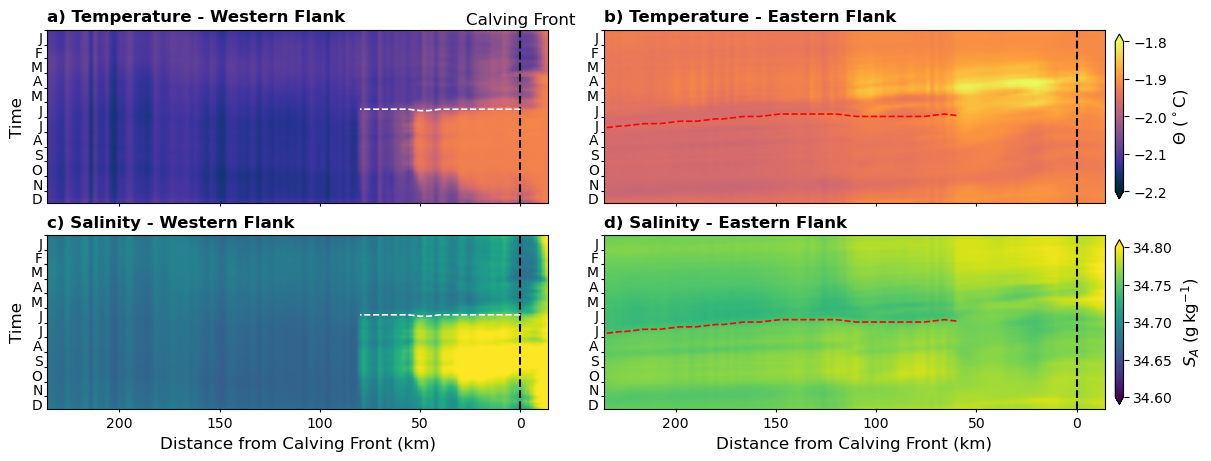

In [27]:
# sharex=True so both transects share the same distance from the calving front axis
fig, ax = plt.subplots(2, len(TRANSECTS), figsize=(12, 4.5), sharex=True, layout='constrained', squeeze=False)

# Track the distance from the calving front along both transects so the shared x axis can be clipped to them
x_lims = []

# Loop over the transects. n is the row number, tname the title, waypoints the path.
for n, (tname, waypoints) in enumerate(TRANSECTS):
    # Turn the waypoints into a dense line of points 1 km apart
    # path_eastings_northings_km = eastings/northings in km, path_along_km = how along path it is in km
    path_eastings_northings_km, path_along_km = interpolate_path(waypoints)

    # Snap every path point to the nearest model cell
    # path_eta_rho = model row, path_xi_rho = model column
    path_eta_rho = np.abs(northings_km_1d[:, None] - path_eastings_northings_km[:, 1]).argmin(axis=0)
    path_xi_rho = np.abs(eastings_km_1d[:, None] - path_eastings_northings_km[:, 0]).argmin(axis=0)

    # Find every ocean cell in a rectangle defined around the path
    # path_eastings_northings_km[:, 0] = path's eastings, path_eastings_northings_km[:, 1] = path's northings
    near = (ocean_mask 
            & (eastings_km_2d >= path_eastings_northings_km[:, 0].min() - BAND_HALF_KM) 
            & (eastings_km_2d <= path_eastings_northings_km[:, 0].max() + BAND_HALF_KM) 
            & (northings_km_2d >= path_eastings_northings_km[:, 1].min() - BAND_HALF_KM) 
            & (northings_km_2d <= path_eastings_northings_km[:, 1].max() + BAND_HALF_KM))
    # Define these near ocean cells in grid coordinates
    cell_eta_rho, cell_xi_rho = np.where(near)
    # Define these near ocean cells in eastings and northings
    cell_eastings_km, cell_northings_km = eastings_km_2d[cell_eta_rho, cell_xi_rho], northings_km_2d[cell_eta_rho, cell_xi_rho]

    # Direction of the path at every path point, as a unit vector (np.gradient gives the local step)
    path_tangent = np.gradient(path_eastings_northings_km, axis=0)
    path_tangent /= np.hypot(path_tangent[:, 0], path_tangent[:, 1])[:, None]
    # Direction perpendicular to the path (tangent rotated 90 degrees)
    path_normal = np.column_stack([-path_tangent[:, 1], path_tangent[:, 0]])

    # Create bins of along-path distance
    bin_edges = np.arange(0, path_along_km[-1] + BIN_KM, BIN_KM)
    bin_centres = (bin_edges[:-1] + bin_edges[1:]) / 2
    # Path point sitting at the middle of each bin
    bin_centre_point = np.clip(np.searchsorted(path_along_km, bin_centres), 0, len(path_along_km) - 1)

    # Initialise arrays to hold the averaged fields with one value per timestep per distance bin
    hov_temp = np.full((len(doy), len(bin_centres)), np.nan)
    hov_salt = np.full((len(doy), len(bin_centres)), np.nan)

    # For each bin, take the cells inside a rectangle centred on the path at that point, aligned with the path
    for b in range(len(bin_centres)):
        k = bin_centre_point[b]
        # Position of every nearby cell relative to the middle of this bin
        offset_e = cell_eastings_km - path_eastings_northings_km[k, 0]
        offset_n = cell_northings_km - path_eastings_northings_km[k, 1]
        # How far each cell is ALONG the path direction, and ACROSS it, from the middle of the bin
        along = offset_e * path_tangent[k, 0] + offset_n * path_tangent[k, 1]
        across = offset_e * path_normal[k, 0] + offset_n * path_normal[k, 1]
        # Keep cells within half a bin along the path and within the band across it
        in_bin = (np.abs(along) <= BIN_KM / 2) & (np.abs(across) <= BAND_HALF_KM)
        if in_bin.any():
            hov_temp[:, b] = np.nanmean(temp_bot[:, cell_eta_rho[in_bin], cell_xi_rho[in_bin]], axis=1)
            hov_salt[:, b] = np.nanmean(salt_bot[:, cell_eta_rho[in_bin], cell_xi_rho[in_bin]], axis=1)

    # True/False for each path point: is it sitting over the cavity?
    on_cavity = cavity_mask[path_eta_rho, path_xi_rho]

    # Find the along-path distance at which the path enters the cavity
    front_s = path_along_km[on_cavity][0] if on_cavity.any() else 0.0

    # Find the distance of each column from the calving front, along the path (negative = seaward of the front)
    col_x = bin_centres - front_s

    # Top row is temperature, bottom row is salinity
    ax_t = ax[0, n]
    ax_s = ax[1, n]

    im_temp = ax_t.pcolormesh(col_x, doy, np.ma.masked_invalid(hov_temp), **temp_kwargs)
    im_salt = ax_s.pcolormesh(col_x, doy, np.ma.masked_invalid(hov_salt), **salt_kwargs)
    # im_temp = ax_t.contourf(col_x, doy, np.ma.masked_invalid(hov_temp), **temp_kwargs)
    # im_salt = ax_s.contourf(col_x, doy, np.ma.masked_invalid(hov_salt), **salt_kwargs)

    # ---------- TRACE THE SALINIFICATION FRONT ON BOTH FLANKS ----------
    if tname == 'Western Flank':
        # >>> NEW: just inside the calving front, where the western rise first appears
        TRACE_DIST = (0, 80)
        line_colour = "white"
    else:
        # Define a window of distance (from calving front in km) to analyse over
        TRACE_DIST = (50, 250)
        line_colour = "red"
    TRACE_DOY = (140, 220)
    # Define the range of distance bins the speed is fitted over
    FIT_DIST = (150, 250)
    # Define the number of timesteps to smooth over before taking the gradient
    SMOOTH_STEPS = 3
    # Number of neighbouring distance bins in the running median for the plotted line
    SMOOTH_BINS = 5
    # Define a mininum salinity increase (g/kg) to ensure we only find points of an actual salinity signal
    MIN_RISE = 0.01

    # Find the timesteps within the define time window
    in_time = (doy >= TRACE_DOY[0]) & (doy <= TRACE_DOY[1])
    doy_window = doy[in_time]

    arrival_dist, arrival_day = [], []
    # Iterate over each distance bin within the distance the window
    for b in np.where((col_x >= TRACE_DIST[0]) & (col_x <= TRACE_DIST[1]))[0]:
        # Skip any empty distance bins
        if np.isnan(hov_salt[:, b]).all():
            continue
                
        # Smooth this bin's salinity over the defined number of timesteps - so small wiggles don't create false spikes in the gradient
        # mode='wrap' because the climatology repeats - 31 Dec runs straight on into 1 Jan
        salt_smooth = uniform_filter1d(hov_salt[:, b], size=SMOOTH_STEPS, mode='wrap')
            
        # Calculate the rate of change (gradient of salinity through time
        salt_rate = np.gradient(salt_smooth, doy)
            
        # Narrow this gradient to just the define timeframe now
        rate_window = salt_rate[in_time]
            
        # Find the arrival time as the timestep where salinity is rising fastest
        steepest = np.nanargmax(rate_window)
            
        # Skip any distance bins where salinity doesn't rise during in the defined timeframe
        if rate_window[steepest] <= 0:
            continue

        # Calculate how much salinity actually increases across the steepest slope
        salt_window = salt_smooth[in_time]
        rise = np.nanmax(salt_window[steepest:]) - np.nanmin(salt_window[:steepest + 1])
        # Skip distances bins where that rise is too small to be a real arrival
        if rise < MIN_RISE:
            continue
                
        arrival_day.append(doy_window[steepest])
        arrival_dist.append(col_x[b])

    arrival_dist, arrival_day = np.array(arrival_dist), np.array(arrival_day)

    # Calculate the earliest arrival date on this flank - i.e. the distance bin whose arrival day is smallest
    earliest = np.argmin(arrival_day)
    # Convert day of year to a calendar date - 2001 is just a non-leap reference year, matching the 365-day climatology
    earliest_date = datetime.date(2001, 1, 1) + datetime.timedelta(days=int(arrival_day[earliest]) - 1)
    print(f"{tname}: earliest arrival DOY {arrival_day[earliest]:.0f} ({earliest_date:%d %b}), {arrival_dist[earliest]:.0f} km from the calving front")

    # Calculate a running median of arrival day along the path
    arrival_smooth = median_filter(arrival_day, size=SMOOTH_BINS, mode='nearest')
    # Calculate a running mean over the same width, to round off the 5-day steps the median leaves
    arrival_smooth = uniform_filter1d(arrival_smooth, size=SMOOTH_BINS, mode='nearest')

    # Plot the smoothed arrival front
    ax_t.plot(arrival_dist, arrival_smooth, '--', color=line_colour, lw=1.2, zorder=10)
    ax_s.plot(arrival_dist, arrival_smooth, '--', color=line_colour, lw=1.2, zorder=10)
    # Draw the arrival front on all four panels, for comparison
    # for panel in ax.ravel():
    #     panel.plot(arrival_dist, arrival_smooth, '--', color=line_colour, lw=1.2, zorder=10)
    
    # Calculate the speed of propagation on the eastern flank only
    if tname == 'Eastern Flank':
        # Use only the bins inside the fitting range to calculate the speed
        in_fit = (arrival_dist >= FIT_DIST[0]) & (arrival_dist <= FIT_DIST[1])

        # Find the best straight line fit of arrival day against distance
        # fit.slope is days per km
        # fit.stderr is the uncertainty on the slope
        fit = linregress(arrival_dist[in_fit], arrival_day[in_fit])
        
        # Invert the slope into km per day - then convert to cm/s (1 km/day = 1e5 cm / 86400 s)
        speed_cm_s = (1 / fit.slope) * 1e5 / 86400
        # Find the relative error that the slope carries across to the speed
        speed_err = abs(speed_cm_s) * fit.stderr / abs(fit.slope)

        # Print the findings on speed
        print(f"Fitted from {arrival_dist[in_fit].min():.0f} to {arrival_dist[in_fit].max():.0f} km from the calving front")
        print(f"Correlation of fitted line: r = {fit.rvalue:.2f}")
        print(f"Propagation speed: {abs(speed_cm_s):.2f} ± {speed_err:.2f} cm/s")

    # Clip the x axis to the data, so shared limits do not leave gaps at either end
    x_lims.append((col_x.min(), col_x.max()))

    # row is 0 for temperature and 1 for salinity.
    for row, axis in enumerate([ax_t, ax_s]):
        # Jan at the top, Dec at the bottom
        axis.invert_yaxis()
        # Ticks at the month boundaries, but unlabelled and invisible
        axis.set_yticks(month_start)
        axis.set_yticklabels([])
        axis.tick_params(axis='y', length=2)
        axis.tick_params(axis='x', length=2)

        # Labels at the midpoint of each month
        month_mid = np.concatenate([month_start, [366]])
        month_mid = (month_mid[:-1] + month_mid[1:]) / 2
        axis.set_yticks(month_mid, minor=True)
        axis.set_yticklabels([m[0] for m in month_names], minor=True)
        axis.tick_params(axis='y', which='minor', length=0)

        # Mark the calving front at zero distance
        if on_cavity.any():
            axis.axvline(0, color='black', linestyle='--', lw=1.5)
            if n == 0 and row == 0:
                axis.annotate('Calving Front', xy=(0, doy.min()), xytext=(0, 2), textcoords='offset points', color='black', ha='center', va='bottom')
                
        # Panel letters run left to right, then down
        variable = 'Temperature' if row == 0 else 'Salinity'
        # Row holds panels row*len(TRANSECTS) onward, so a/b along the top and c/d along the bottom
        axis.set_title(f'{panel_labels[row * len(TRANSECTS) + n]}) {variable} - {tname}', loc='left', fontweight="bold")

    # Label time only on the left
    # Both rows of the left-hand column carry the time label
    if n == 0:
        ax_t.set_ylabel('Time')
        ax_s.set_ylabel('Time')

ax[-1, 0].set_xlabel('Distance from Calving Front (km)')
ax[-1, 1].set_xlabel('Distance from Calving Front (km)')

# Distance increases leftward, keeping the calving front on the right
ax[0, 0].set_xlim(min(hi for lo, hi in x_lims), max(lo for lo, hi in x_lims))

# Shared colourbars beside each row
# One colourbar per ROW, to the right, since each row is one variable
cbar_t = fig.colorbar(im_temp, ax=ax[0, :], location='right', shrink=0.95, pad=0.01, aspect=20, extend='both')
cbar_t.set_label(r'$\Theta$ ($^\circ$C)')
cbar_s = fig.colorbar(im_salt, ax=ax[1, :], location='right', shrink=0.95, pad=0.01, aspect=20, extend='both')
cbar_s.set_label(r'$S_A$ ($\mathrm{g\,kg^{-1}}$)')

fig.canvas.draw()
fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ModelHSSWHovmoller.jpg', format='jpg', dpi=300)
plt.show()

### Determine Transect Geometry

In [14]:
# First pass: rebuild each transect's path and bins exactly as the Hovmoller does, keeping the cells in every bin
transect_geometry = {}
for tname, waypoints in TRANSECTS:
    # The smoothed path, and every nearby ocean cell
    path_eastings_northings_km, path_along_km = interpolate_path(waypoints)
    near = (ocean_mask
            & (eastings_km_2d >= path_eastings_northings_km[:, 0].min() - BAND_HALF_KM)
            & (eastings_km_2d <= path_eastings_northings_km[:, 0].max() + BAND_HALF_KM)
            & (northings_km_2d >= path_eastings_northings_km[:, 1].min() - BAND_HALF_KM)
            & (northings_km_2d <= path_eastings_northings_km[:, 1].max() + BAND_HALF_KM))
    cell_eta_rho, cell_xi_rho = np.where(near)
    cell_eastings_km, cell_northings_km = eastings_km_2d[cell_eta_rho, cell_xi_rho], northings_km_2d[cell_eta_rho, cell_xi_rho]

    # Direction of the path at every path point, and the direction perpendicular to it
    path_tangent = np.gradient(path_eastings_northings_km, axis=0)
    path_tangent /= np.hypot(path_tangent[:, 0], path_tangent[:, 1])[:, None]
    path_normal = np.column_stack([-path_tangent[:, 1], path_tangent[:, 0]])

    # Distance bins along the path, and the path point at the middle of each
    bin_edges = np.arange(0, path_along_km[-1] + BIN_KM, BIN_KM)
    bin_centres = (bin_edges[:-1] + bin_edges[1:]) / 2
    bin_centre_point = np.clip(np.searchsorted(path_along_km, bin_centres), 0, len(path_along_km) - 1)

    # For each bin, the cells inside its rectangle - half a bin along the path, the band half-width across it
    bin_cells = []
    for b in range(len(bin_centres)):
        k = bin_centre_point[b]
        offset_e = cell_eastings_km - path_eastings_northings_km[k, 0]
        offset_n = cell_northings_km - path_eastings_northings_km[k, 1]
        along = offset_e * path_tangent[k, 0] + offset_n * path_tangent[k, 1]
        across = offset_e * path_normal[k, 0] + offset_n * path_normal[k, 1]
        in_bin = (np.abs(along) <= BIN_KM / 2) & (np.abs(across) <= BAND_HALF_KM)
        bin_cells.append((cell_eta_rho[in_bin], cell_xi_rho[in_bin]))

    # Where the path enters the cavity, and each bin's distance from the calving front (as the Hovmoller x axis)
    path_eta_rho = np.abs(northings_km_1d[:, None] - path_eastings_northings_km[:, 1]).argmin(axis=0)
    path_xi_rho = np.abs(eastings_km_1d[:, None] - path_eastings_northings_km[:, 0]).argmin(axis=0)
    on_cavity = cavity_mask[path_eta_rho, path_xi_rho]
    front_s = path_along_km[on_cavity][0] if on_cavity.any() else 0.0
    col_x = bin_centres - front_s

    transect_geometry[tname] = dict(path=path_eastings_northings_km, path_along_km=path_along_km, front_s=front_s,
                                    path_eta_rho=path_eta_rho, path_xi_rho=path_xi_rho, col_x=col_x, bin_cells=bin_cells)

# The distance range shared by both transects - exactly the range the Hovmoller x axis is clipped to
shared_lo = max(g['col_x'].min() for g in transect_geometry.values())
shared_hi = min(g['col_x'].max() for g in transect_geometry.values())

# Second pass: keep only the part of each transect that is actually shown in the Hovmoller
for tname, g in transect_geometry.items():
    transect_mask = np.zeros(ocean_mask.shape, dtype=bool)     # cells the path runs through
    band_mask = np.zeros(ocean_mask.shape, dtype=bool)         # every cell averaged into a shown bin

    # Bins whose distance from the front falls within the shared range
    for b in np.where((g['col_x'] >= shared_lo) & (g['col_x'] <= shared_hi))[0]:
        band_mask[g['bin_cells'][b]] = True

    # Path points within the shared range (widened by half a bin, to match the outer edges of the end bins)
    path_distance = g['path_along_km'] - g['front_s']
    path_shown = (path_distance >= shared_lo - BIN_KM / 2) & (path_distance <= shared_hi + BIN_KM / 2)
    transect_mask[g['path_eta_rho'][path_shown], g['path_xi_rho'][path_shown]] = True

    g['path_shown'] = path_shown
    g['transect_mask'] = transect_mask
    g['band_mask'] = band_mask

### PLOT - Transect Map

<Figure size 640x480 with 0 Axes>

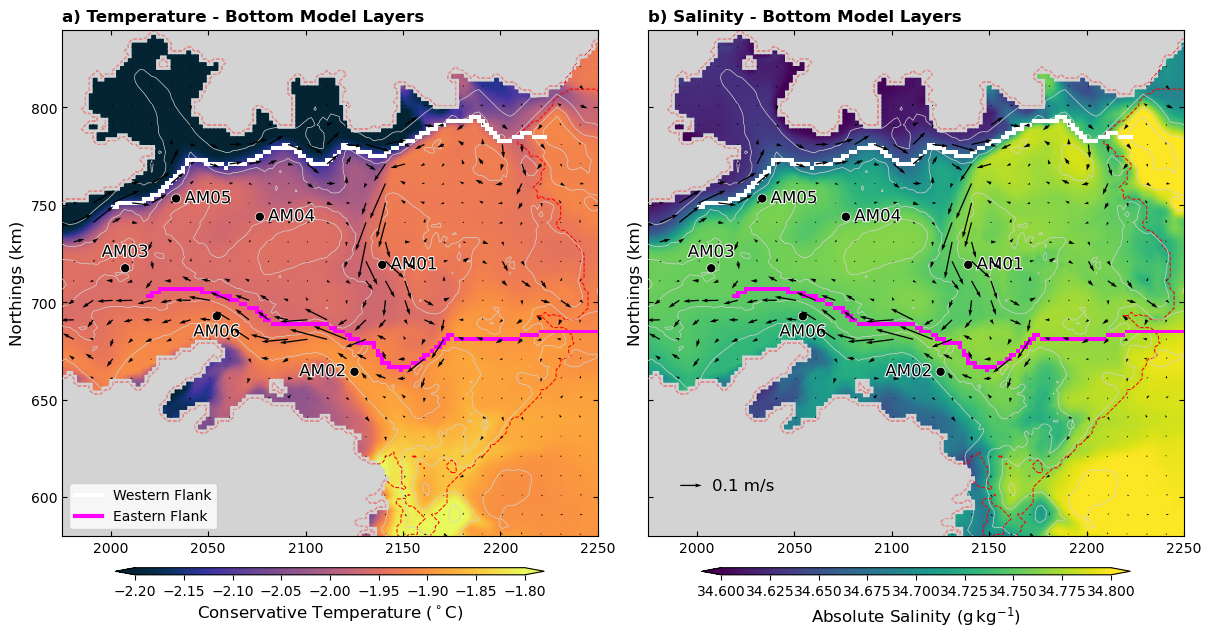

In [28]:
plt.cla()
plt.clf()

# Quiver settings
res = 5
vel_scale = 2.5

# Colour for each transect - chosen to show up over both the temperature and salinity colourmaps
TRANSECT_COLOURS = {'Western Flank': 'white', 'Eastern Flank': 'magenta'}

# ---------- OCEAN CONDITIONS: BOTTOM MODEL LAYERS ----------
# Vertical layers to average over - s_rho index 0 is the bed
choose_depth = [0, 1, 2, 3, 4]
# Compute the layer thicknesses for the chosen levels
dz_bot = ds_CTRL.dz.isel(s_rho=choose_depth)
# Calculate the total thickness of all chosen levels
dz_sum = dz_bot.sum('s_rho')
# Compute the temperature, salinity and velocity fields across the chosen levels weighted by layer thickness
temp_bot_annual = ((ds_CTRL.temp_doy.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum).mean('dayofyear')
salt_bot_annual = ((ds_CTRL.salt_doy.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum).mean('dayofyear')
u_bot_annual = ((ds_CTRL.u_rho_doy.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum).mean('dayofyear')
v_bot_annual = ((ds_CTRL.v_rho_doy.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum).mean('dayofyear')

# ---------- PLOT ----------
fig, ax = plt.subplots(1, 2, figsize=(12, 6.5), layout='constrained')

for i in range(2):
    ax[i].set_facecolor('lightgrey')

# ---------- TEMPERATURE (BOTTOM) ----------
ax0=ax[0].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_bot_annual, **temp_kwargs)
ax[0].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], u_bot_annual.values[0::res,0::res], v_bot_annual.values[0::res,0::res],scale=vel_scale, zorder=9)

# ---------- SALINITY (BOTTOM) ----------
ax1=ax[1].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_bot_annual, **salt_kwargs)
qu = ax[1].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], u_bot_annual.values[0::res,0::res], v_bot_annual.values[0::res,0::res],scale=vel_scale, zorder=9)

# Draw each transect on BOTH panels, in its own colour
for i in range(2):
    for tname, g in transect_geometry.items():
        colour = TRANSECT_COLOURS[tname]

        # Cells the transect runs through, filled with the transect's colour. masked_where hides every other cell.
        ax[i].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, np.ma.masked_where(~g['transect_mask'], g['transect_mask'].astype(float)),
                         cmap=mcolors.ListedColormap([colour]), shading='nearest', zorder=8)

        # Outline of the band of averaged cells - contouring the mask at 0.5 traces the edge of the outermost used cells
        # ax[i].contour(ds_CTRL.x_rho, ds_CTRL.y_rho, g['band_mask'].astype(float), levels=[0.5], colors=colour, linestyles='--', linewidths=1.5, zorder=8)

scale_ticks = 1e3
ticks_x = mticker.FuncFormatter(lambda x, pos: '{0:g}'.format(x/scale_ticks))
ticks_y = mticker.FuncFormatter(lambda x, pos: '{0:g}'.format(x/scale_ticks))

for i in range(2):
    ax[i].set_title('')
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].tick_params(axis="both", direction="in", top=True, right=True)
    ax[i].set_ylabel('Northings (km)')
    style_map(ds_CTRL, ax[i], boreholes_amisor, wct_colour='lightgrey')
    
ax[0].set_title('a) Temperature - Bottom Model Layers', loc='left', fontweight='bold')
ax[1].set_title('b) Salinity - Bottom Model Layers', loc='left', fontweight='bold')

ax[0].set_ylabel('Northings (km)')
ax[1].tick_params(labelleft=False)

# Reference arrow for the currents
ax[1].quiverkey(qu, 0.1, 0.1, 0.1, '0.1 m/s', coordinates='axes', labelpos='E')

# Legend identifying each transect by colour
transect_handles = [Line2D([0], [0], color=TRANSECT_COLOURS[tname], lw=3, label=tname) for tname in transect_geometry]
ax[0].legend(handles=transect_handles, loc='lower left', frameon=True)

# Colourbars beneath each panel
cbar_t = fig.colorbar(ax0, ax=ax[0], location='bottom', shrink=0.8, pad=0.02, aspect=60, extend='both')
cbar_t.set_label(r'Conservative Temperature ($^\circ$C)')
cbar_s = fig.colorbar(ax1, ax=ax[1], location='bottom', shrink=0.8, pad=0.02, aspect=60, extend='both')
cbar_s.set_label(r'Absolute Salinity ($\mathrm{g\,kg^{-1}}$)')

fig.canvas.draw()
fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ModelHovmollerTransectsMap.jpg', format='jpg', dpi=300)
plt.show()